# Depth and freshness, not learned prediction: a walk through the results

This notebook walks through every experiment of the project in the order of
the talk and the paper (`paper/main.tex`): the data, the disk simulation
(E1), the GPU-trained predictors (E2), the real-device testbed (E3), the web
replay (E4, E5), the live HTTP replay (E6), the pre-registered decisions,
and the classifier studies that came after them (E7 and later).

**Every number below is computed by a code cell from the tracked `results/`
tree.** Nothing is typed by hand; the markdown only says which file and
which paper section or table a cell corresponds to. Rebuild it after new
results land with `python reproduce.py notebook`.

How to read it:

- **Simulated or measured.** E1, E2, E4 and E5 are *simulated* (a causal
  cache replay): their hit ratios are not latencies. Latency is *measured*
  only in E3 (`results/realio/`, a real HDD `sdb` and a shared SSD) and E6
  (`results/live/`, loopback with an emulated network and assumed object
  sizes).
- **Hit ratio is not device work.** Every disk hit-ratio difference is shown
  next to the `device_ios` and `blocks_moved` ratios against `none`.
- **Pre-registered words only.** "better", "worse" and "no difference
  detected" come from each study's `results/<study>/PREREGISTERED.md`; the
  verdict columns are computed by `paper/decisions.py`, the same code that
  writes the paper's verdict macros. On disk, the paired and the
  corpus-cluster bootstrap intervals must agree.
- **`belady_min`** is Belady's MIN for demand paging *without* prefetch: a
  reference for replacement, not an upper bound for prefetching policies.
- **Flagged rows are not cited.** SSD rows carry `foreign_io_frac` (other
  tenants' I/O); a row above the 1% limit, a busy-host row or an invalid
  live pass is shown as flagged and kept out of every comparison.

## 0. Setup

The first cell finds the repository root, puts `src/` on `sys.path` (so no
`PYTHONPATH` is needed in the kernel) and loads `paper/genlib.py` and
`paper/decisions.py` **by file path**: `paper/` must never be on `sys.path`,
because `paper/numbers.py` would shadow the standard library's `numbers`.
The kernel needs the `[web,paper]` extras (pandas, numpy, matplotlib, scipy).

In [1]:
import importlib.util
import json
import os
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / "reproduce.py").is_file() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
os.chdir(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

try:
    display
except NameError:  # outside IPython
    from IPython.display import display

pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.max_rows", 400)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 90, "savefig.dpi": 90, "figure.figsize": (9, 3.6),
                     "axes.grid": True, "grid.alpha": 0.3})


def load_by_path(name, relative):
    """Import a paper/ script by file path (never put paper/ on sys.path)."""
    if name not in sys.modules:
        spec = importlib.util.spec_from_file_location(name, ROOT / relative)
        module = importlib.util.module_from_spec(spec)
        sys.modules[name] = module
        spec.loader.exec_module(module)
    return sys.modules[name]


genlib = load_by_path("paper_genlib", "paper/genlib.py")
decisions = load_by_path("paper_decisions", "paper/decisions.py")
RESULTS = ROOT / "results"
TREE = genlib.Results(RESULTS)        # schema-checked reader shared with the paper


def csv(relative):
    return pd.read_csv(RESULTS / relative)


def ci(lo, hi, scale=1.0, digits=2):
    """'[lo, hi]' with a fixed format; '--' when either end is missing."""
    if lo is None or hi is None or pd.isna(lo) or pd.isna(hi):
        return "--"
    return f"[{lo * scale:.{digits}f}, {hi * scale:.{digits}f}]"


def fmt_interval(item):
    label, estimate, lo, hi, statistic = item
    scale, digits, unit = {"difference": (100, 2, " pp"), "absolute": (100, 2, " pp"),
                           "ratio": (1, 3, "x"), "us": (1, 0, " us"),
                           "ms": (1, 2, " ms"), "rho": (1, 3, "")}.get(statistic, (1, 4, ""))
    head = f"{label}: " if label else ""
    point = "--" if estimate is None else f"{estimate * scale:.{digits}f}{unit}"
    if lo is None or hi is None:
        return head + point
    return head + f"{point} {ci(lo, hi, scale, digits)}"


DECISIONS = decisions.decide(TREE)


def decision_frame(study=None, rules=None, scope_contains=None):
    """The pre-registered verdicts of paper/decisions.py as a table."""
    rows = []
    for d in DECISIONS:
        if study and d.study != study:
            continue
        if rules and d.rule not in rules:
            continue
        if scope_contains and scope_contains not in d.scope:
            continue
        rows.append({"study": d.study, "rule": d.rule, "scope": d.scope,
                     "comparison": d.comparison, "verdict": d.verdict,
                     "interval(s)": "; ".join(fmt_interval(i) for i in d.intervals),
                     "note": d.note})
    return pd.DataFrame(rows)


print(f"{len(DECISIONS)} pre-registered verdicts computed from results/")

1045 pre-registered verdicts computed from results/


### Provenance of every results directory

Each results directory carries a `provenance.json` with the SHA-256 of every
file it holds; `prefetch_common.provenance.verify_provenance` re-hashes them.
An empty "problems" column means no file was edited after its reproduce
command wrote it.

In [2]:
from prefetch_common import provenance

rows = []
for directory in sorted(p for p in RESULTS.iterdir() if p.is_dir()):
    record_path = directory / "provenance.json"
    if not record_path.is_file():
        rows.append({"directory": directory.name, "files": None, "git_sha": None,
                     "problems": "no provenance.json yet"})
        continue
    record = json.loads(record_path.read_text())
    problems = provenance.verify_provenance(directory)
    rows.append({"directory": directory.name, "files": len(record.get("outputs", {})),
                 "git_sha": (record.get("git_sha") or "")[:10],
                 "problems": "; ".join(problems)})
pd.DataFrame(rows)

,directory,files,git_sha,problems
0,claims,2,10cbe1d6b5,
1,classifier,8,96b4dd8e21,
2,disk,8,beea45c300,
3,gpu,4,f44afe72ef,
4,hindsight,7,32f8bdda76,
5,live,7,ae492d5dfa,
6,msrc_samples,6,739b599710,
7,pivot_original,17,8569cdf476,
8,realio,5,aa382c1f7c,
9,web,11,6de973bf2d,


## 1. Data and corpora

**Disk.** The libCacheSim `oracleGeneral` block traces from four corpora
(MSR, FIU, Alibaba, Tencent). Writes replay as reads and the traces carry no
service times, so oracle-trace hit ratios are never compared with
MSRC-trace-003 figures. Source: `results/disk/corpus_profile.csv`; paper
Table `t1_datasets` (Sec. Methodology).

In [3]:
profile = csv("disk/corpus_profile.csv")
by_corpus = profile.groupby("corpus").agg(
    traces=("trace", "count"), paper_subset=("paper_subset", "sum"),
    requests=("requests", "sum"), blocks=("blocks", "sum"),
    median_mean_request_blocks=("mean_request_blocks", "median"),
    median_contiguous_fraction=("contiguous_fraction", "median"),
    twin_grouped=("twin_group", lambda s: int(s.notna().sum())))
by_corpus.loc["all"] = [len(profile), int(profile["paper_subset"].sum()),
                        int(profile["requests"].sum()), int(profile["blocks"].sum()),
                        profile["mean_request_blocks"].median(),
                        profile["contiguous_fraction"].median(),
                        int(profile["twin_group"].notna().sum())]
by_corpus

,traces,paper_subset,requests,blocks,median_mean_request_blocks,median_contiguous_fraction,twin_grouped
corpus,,,,,,,
alibaba,20,6,437317645,17971428621,40.2702,0.0706,12
fiu,10,4,78348519,4161279035,27.9159,0.0313,0
msr,14,6,409758161,21148727491,67.1199,0.1308,0
tencent,12,5,89675046,5317763913,72.6386,0.2562,3
all,56,21,1015099371,48599199060,38.3505,0.0839,15


**Web.** RetailRocket product views, sessions broken after 30 minutes and at
every split boundary; split 0 builds the index, split 1 trains the ranker,
split 2 is the only split choices are made on, split 3 is replayed once.
Source: `results/web/dataset_profile.json`; paper Table `t4_web_dataset`.

In [4]:
web_profile = json.loads((RESULTS / "web/dataset_profile.json").read_text())
scalars = {k: v for k, v in web_profile.items() if isinstance(v, (int, float, str, bool))
           and k not in ("source",)}
display(pd.DataFrame({"value": scalars}).astype(str))
splits = pd.DataFrame({key: web_profile[key] for key in
                       ("views_by_split", "eligible_pairs_by_split") if key in web_profile})
splits.index.name = "split"
splits

,value
dataset_version,2
source_verified,True
session_gap_minutes,30
raw_sha256,3745aa83238b1e6d44d8fda209807899f420084398f94d...
raw_rows,2756101
duplicate_rows_removed,460
views,2664218
visitors,1407580
sessions,1755863
sessions_with_2plus_views,367474


,views_by_split,eligible_pairs_by_split
split,,
0,1065687,384445
1,532844,181373
2,532843,174057
3,532844,168480


## 2. E1: disk read-ahead in simulation

**Simulated.** Every trace is replayed through the causal LRU simulator by
every mode; the headline is configuration C1 (canonical merge, the assumed
5/100/50 latency model) at its two capacities. Sources:
`results/disk/table_main.csv` and `results/disk/deltas.csv`; paper
Sec. Disk Results (`sections/disk_results.tex`), Table `t2_disk_main`.

### 2.1 The main table

Mean per-trace hit ratio, its difference from `none` (percentage points,
paired bootstrap interval), and next to it the device work: `device_ios`
and `blocks_moved` as ratios to `none` (above 1 means more device work than
no prefetching). Precision, wasted share and the win count are shown
together, never a win count alone. `belady_min` is a replacement reference
without prefetch, not a prefetching bound.

In [5]:
main = csv("disk/table_main.csv")
headline = main[(main["config"] == "C1") & (main["merge"] == "auto")
                & (main["latency"] == "assumed") & (main["corpus"] == "all")].copy()
headline["capacity"] = headline["capacity"].map(genlib.capacity_label)
for name in ("wins_vs_none", "losses_vs_none"):
    headline[name] = headline[name].astype("Int64")
headline["hit_ratio_%"] = 100 * headline["mean_hit_ratio"]
headline["vs_none_pp"] = 100 * headline["delta_vs_none"]
headline["vs_none_CI_pp"] = [ci(lo, hi, 100) for lo, hi in
                             zip(headline["delta_vs_none_lo"], headline["delta_vs_none_hi"])]
columns = ["capacity", "policy", "n_traces", "hit_ratio_%", "vs_none_pp", "vs_none_CI_pp",
           "device_io_ratio", "blocks_moved_ratio", "mean_precision", "mean_wasted_share",
           "wins_vs_none", "losses_vs_none"]
for capacity, table in headline.groupby("capacity", sort=False):
    print(f"C1, capacity {capacity}, all corpora (simulated)")
    display(table[columns].set_index(["capacity", "policy"]))

C1, capacity 1 MiB, all corpora (simulated)


n_traces  hit_ratio_%  vs_none_pp   vs_none_CI_pp  device_io_ratio  blocks_moved_ratio  mean_precision  mean_wasted_share  wins_vs_none  losses_vs_none
capacity policy                                                                                                                                                                    
1 MiB    none                     56      14.8550         NaN              --              NaN                 NaN             NaN                NaN          <NA>            <NA>
         sequential               56      16.7111      1.8561    [1.07, 2.93]           1.0548              1.0417          0.4900             0.5100            51               5
         strided                  56      14.8625      0.0075   [-0.07, 0.06]           1.0844              1.0031          0.5227             0.4773            48               4
         stride                   56      15.1804      0.3254    [0.06, 0.79]           1.0942              1.0013          0.6740             0.3260            51               5
         markov                   56      15.4080      0.5530    [0.21, 1.12]           1.3931              1.0086          0.5474             0.4526            55               1
         adaptive                 56      15.7712      0.9162    [0.37, 1.85]           1.0779              1.0082          0.5916             0.4084            52               4
         adaptive_evidence        56      16.1581      1.3031    [0.71, 2.28]           1.0969              1.0140          0.5518             0.4482            52               4
         guard                    56      16.2552      1.4002    [0.70, 2.46]           1.0258              1.0097          0.5147             0.4853            51               5
         depth_adaptive           56      18.1528      3.2978    [1.92, 4.94]           1.0224              1.0139          0.5324             0.4676            51               5
         correlate                56      15.7421      0.8871    [0.28, 1.95]           1.1066              1.0060          0.5037             0.4963            52               4
         deep@8                   56      21.0265      6.1715    [4.28, 8.10]           1.0660              1.1690          0.4776             0.5224            52               4
         deep@32                  56      31.0628     16.2078  [12.63, 19.70]           1.1428              1.6750          0.4183             0.5817            54               2
         deep@256                 56      50.4147     35.5597  [29.03, 41.86]           1.3093              7.0153          0.1928             0.8072            51               5
         linux_ra@64              56      21.7084      6.8534    [4.88, 9.03]           0.8589              1.0218          0.7472             0.2528            53               0
         linux_ra@256             56      38.6214     23.7664  [19.47, 28.35]           0.7401              1.0861          0.7698             0.2302            56               0
         linux_ra@1024            56      45.4104     30.5554  [25.98, 35.25]           0.7202              1.2669          0.5914             0.4086            56               0
         belady_min               56      22.7901      7.9351   [5.56, 10.46]              NaN                 NaN             NaN                NaN            56               0

C1, capacity 64 MiB, all corpora (simulated)


n_traces  hit_ratio_%  vs_none_pp   vs_none_CI_pp  device_io_ratio  blocks_moved_ratio  mean_precision  mean_wasted_share  wins_vs_none  losses_vs_none
capacity policy                                                                                                                                                                    
64 MiB   none                     56      28.3310         NaN              --              NaN                 NaN             NaN                NaN          <NA>            <NA>
         sequential               56      30.0710      1.7400    [1.41, 2.11]           1.0241              1.0137          0.6941             0.3059            56               0
         strided                  56      28.3785      0.0475    [0.02, 0.08]           1.0894              1.0007          0.5627             0.4373            51               1
         stride                   56      28.4428      0.1118    [0.06, 0.17]           1.0879              1.0003          0.7643             0.2357            55               1
         markov                   56      28.6340      0.3030    [0.24, 0.38]           1.3576              1.0026          0.7299             0.2701            56               0
         adaptive                 56      28.8651      0.5341    [0.40, 0.68]           1.0890              1.0027          0.7279             0.2721            56               0
         adaptive_evidence        56      29.2662      0.9352    [0.76, 1.13]           1.0976              1.0050          0.7534             0.2466            56               0
         guard                    56      29.8470      1.5160    [1.17, 1.89]           1.0260              1.0069          0.7373             0.2627            56               0
         depth_adaptive           56      33.1184      4.7874    [3.44, 6.27]           1.0299              1.0119          0.7680             0.2320            56               0
         correlate                56      29.0667      0.7358    [0.51, 1.02]           1.2253              1.0042          0.6939             0.3061            56               0
         deep@8                   56      35.1348      6.8038    [5.55, 8.23]           1.0054              1.0554          0.6921             0.3079            55               1
         deep@32                  56      45.9133     17.5823  [14.96, 20.56]           1.0077              1.1885          0.6615             0.3385            56               0
         deep@256                 56      77.8084     49.4774  [43.50, 55.62]           1.1474              2.2563          0.5246             0.4754            56               0
         linux_ra@64              56      35.3276      6.9966    [5.21, 8.95]           0.7822              1.0127          0.8452             0.1548            52               1
         linux_ra@256             56      55.3532     27.0222  [22.25, 32.01]           0.5765              1.0387          0.9015             0.0985            55               1
         linux_ra@1024            56      71.6801     43.3491  [36.73, 50.30]           0.4462              1.0778          0.8759             0.1241            55               1
         belady_min               56      38.2019      9.8709   [7.73, 12.21]              NaN                 NaN             NaN                NaN            56               0

### 2.2 Differences with both intervals and the pre-registered verdict

For each mode: the hit-ratio difference against `none` and against
`sequential`, each with the paired and the corpus-cluster bootstrap interval
(twins down-weighted), and the verdict of the disk rule (both intervals must
agree; `decisions.disk_verdict`). The `device_ios` and `blocks_moved` ratios
against `none`, with their paired intervals, stand next to them. Source:
`results/disk/deltas.csv`.

In [6]:
deltas = csv("disk/deltas.csv")
c1 = deltas[(deltas["config"] == "C1") & (deltas["merge"] == "auto")
            & (deltas["latency"] == "assumed") & (deltas["corpus"] == "all")]


def pick(metric, baseline):
    part = c1[(c1["metric"] == metric) & (c1["baseline"] == baseline)]
    return part.set_index(["capacity", "policy"])


hit_none, hit_seq = pick("hit_ratio", "none"), pick("hit_ratio", "sequential")
ios, moved = pick("device_ios", "none"), pick("blocks_moved", "none")
rows = []
for key, h in hit_none.iterrows():
    row = {"capacity": genlib.capacity_label(key[0]), "policy": key[1], "n": h["n"],
           "hit_vs_none_pp": 100 * h["estimate"],
           "paired_CI": ci(h["ci_lo"], h["ci_hi"], 100),
           "cluster_CI": ci(h["cluster_ci_lo"], h["cluster_ci_hi"], 100),
           "verdict_vs_none": decisions.disk_verdict((h["ci_lo"], h["ci_hi"]),
                                                     (h["cluster_ci_lo"], h["cluster_ci_hi"]))}
    if key in hit_seq.index:
        s = hit_seq.loc[key]
        row["hit_vs_sequential_pp"] = 100 * s["estimate"]
        row["verdict_vs_sequential"] = decisions.disk_verdict(
            (s["ci_lo"], s["ci_hi"]), (s["cluster_ci_lo"], s["cluster_ci_hi"]))
    for name, frame in (("device_ios", ios), ("blocks_moved", moved)):
        if key in frame.index:
            r = frame.loc[key]
            row[f"{name}_ratio"] = r["estimate"]
            row[f"{name}_CI"] = ci(r["ci_lo"], r["ci_hi"], 1, 3)
    rows.append(row)
pd.DataFrame(rows).set_index(["capacity", "policy"])

n  hit_vs_none_pp       paired_CI      cluster_CI         verdict_vs_none  device_ios_ratio   device_ios_CI  blocks_moved_ratio blocks_moved_CI  hit_vs_sequential_pp  \
capacity policy                                                                                                                                                                                      
1 MiB    sequential         56          1.8561    [1.07, 2.93]    [0.63, 3.50]                  better            1.0548  [1.031, 1.089]              1.0417  [1.028, 1.059]                   NaN   
         strided            56          0.0075   [-0.07, 0.06]   [-0.14, 0.09]  no difference detected            1.0844  [1.034, 1.152]              1.0031  [1.000, 1.008]               -1.8486   
         stride             56          0.3254    [0.06, 0.79]    [0.06, 1.12]                  better            1.0942  [1.059, 1.136]              1.0013  [1.001, 1.003]               -1.5307   
         markov             56          0.5530    [0.21, 1.12]    [0.19, 1.50]                  better            1.3931  [1.308, 1.495]              1.0086  [1.005, 1.015]               -1.3031   
         adaptive           56          0.9162    [0.37, 1.85]    [0.18, 2.56]                  better            1.0779  [1.032, 1.144]              1.0082  [1.004, 1.014]               -0.9400   
         adaptive_evidence  56          1.3031    [0.71, 2.28]    [0.49, 2.93]                  better            1.0969  [1.063, 1.139]              1.0140  [1.010, 1.019]               -0.5530   
         guard              56          1.4002    [0.70, 2.46]    [0.46, 3.05]                  better            1.0258  [1.016, 1.037]              1.0097  [1.006, 1.014]               -0.4559   
         depth_adaptive     56          3.2978    [1.92, 4.94]    [1.10, 5.14]                  better            1.0224  [1.010, 1.035]              1.0139  [1.009, 1.021]                1.4417   
         correlate          56          0.8871    [0.28, 1.95]    [0.16, 2.92]                  better            1.1066  [1.077, 1.141]              1.0060  [1.004, 1.008]               -0.9690   
         deep@8             56          6.1715    [4.28, 8.10]    [2.98, 8.41]                  better            1.0660  [1.030, 1.118]              1.1690  [1.114, 1.240]                4.3154   
         deep@32            56         16.2078  [12.63, 19.70]  [10.51, 18.72]                  better            1.1428  [1.076, 1.227]              1.6750  [1.454, 1.957]               14.3517   
         deep@256           56         35.5597  [29.03, 41.86]  [23.81, 47.82]                  better            1.3093  [1.188, 1.444]              7.0153  [5.285, 9.219]               33.7035   
         linux_ra@64        56          6.8534    [4.88, 9.03]    [4.22, 9.63]                  better            0.8589  [0.813, 0.900]              1.0218  [1.014, 1.032]                4.9973   
         linux_ra@256       56         23.7664  [19.47, 28.35]  [15.02, 27.99]                  better            0.7401  [0.687, 0.791]              1.0861  [1.064, 1.111]               21.9102   
         linux_ra@1024      56         30.5554  [25.98, 35.25]  [21.52, 37.53]                  better            0.7202  [0.666, 0.774]              1.2669  [1.223, 1.314]               28.6993   
         belady_min         56          7.9351   [5.56, 10.46]   [4.87, 12.49]                  better               NaN             NaN                 NaN             NaN                   NaN   
64 MiB   sequential         56          1.7400    [1.41, 2.11]    [1.26, 2.06]                  better            1.0241  [1.016, 1.033]              1.0137  [1.010, 1.018]                   NaN   
         strided            56          0.0475    [0.02, 0.08]    [0.02, 0.10]                  better            1.0894  [1.038, 1.159]              1.0007  [1.000, 1.001]               -1.6925   
         stride             56          0.1118    [0.06, 0.17]    [0.

### 2.3 The pre-registered disk decisions (P1-P6, the lever ordering, C3, C4)

Computed by `paper/decisions.py` from the same files; these are the verdict
sentences the paper prints (`\dec...` macros, Table `t9_decisions`).

In [7]:
decision_frame("disk", rules={"P1", "P2", "P3", "P4", "P5", "P6", "levers", "C3", "C4"})

,study,rule,scope,comparison,verdict,interval(s),note
0,disk,P1,1 MiB,"adaptive - sequential, hit ratio",worse,"paired: -0.94 pp [-1.31, -0.58]; cluster: -0.8...",n = 56 traces
1,disk,P1,64 MiB,"adaptive - sequential, hit ratio",worse,"paired: -1.21 pp [-1.52, -0.92]; cluster: -1.0...",n = 56 traces
2,disk,P2,1 MiB,"guard - sequential, hit ratio",paired interval only; not robust to corpus clu...,"paired: -0.46 pp [-0.73, -0.14]; cluster: -0.4...",n = 56 traces
3,disk,P2,64 MiB,"guard - sequential, hit ratio",worse,"paired: -0.22 pp [-0.30, -0.16]; cluster: -0.2...",n = 56 traces
4,disk,P2,"1 MiB, break-even cost model","guard - sequential, hit ratio",worse,"paired: -1.65 pp [-2.61, -0.96]; cluster: -1.6...",n = 56 traces
5,disk,P2,"64 MiB, break-even cost model","guard - sequential, hit ratio",worse,"paired: -1.51 pp [-1.84, -1.23]; cluster: -1.4...",n = 56 traces
6,disk,P3,1 MiB,"deep@8 - none, hit ratio",better,"paired: 6.17 pp [4.28, 8.10]; cluster: 5.79 pp...",n = 56 traces
7,disk,P3,64 MiB,"deep@8 - none, hit ratio",better,"paired: 6.80 pp [5.55, 8.23]; cluster: 6.31 pp...",n = 56 traces
8,disk,P3,1 MiB,"deep@32 - none, hit ratio",better,"paired: 16.21 pp [12.63, 19.70]; cluster: 14.9...",n = 56 traces
9,disk,P3,64 MiB,"deep@32 - none, hit ratio",better,"paired: 17.58 pp [14.96, 20.56]; cluster: 16.1...",n = 56 traces


### 2.4 Hit ratio and device I/O against read-ahead depth

Configuration C2 (four capacities, a depth grid, all corpora). The left
panel is the simulated hit ratio, the right panel the device-I/O ratio to
`none` at the same depth: deeper read-ahead raises the hit ratio *and* the
device work under the per-block, no-merge cost model. Source:
`results/disk/table_main.csv`; paper Fig. `f2_hit_vs_depth` (per corpus) and
`f3_device_io_vs_hit`.

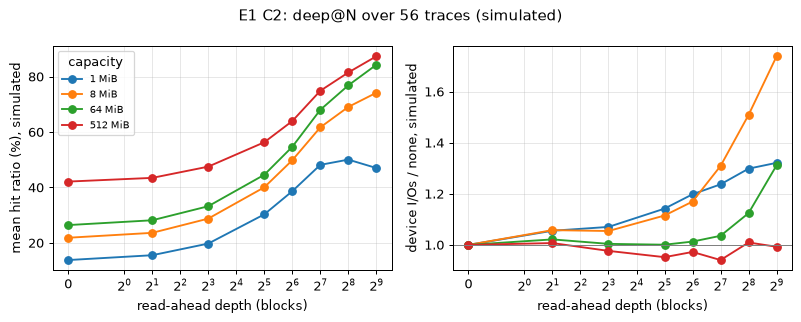

capacity,2048,16384,131072,1048576
depth,,,,
0,0.1381,0.2186,0.2643,0.4213
2,0.1555,0.2363,0.2816,0.4346
8,0.1975,0.2876,0.3323,0.4752
32,0.3030,0.4006,0.4458,0.5631
64,0.3865,0.4983,0.5468,0.6397
128,0.4816,0.6170,0.6802,0.7489
256,0.5006,0.6907,0.7686,0.8150
512,0.4702,0.7418,0.8428,0.8734


In [8]:
c2 = main[(main["config"] == "C2") & (main["merge"] == "auto") & (main["latency"] == "assumed")
          & (main["corpus"] == "all") & main["policy"].str.startswith("deep@")].copy()
c2["depth"] = c2["policy"].str.split("@").str[1].astype(int)
fig, (left, right) = plt.subplots(1, 2, figsize=(9, 3.6))
for capacity, part in c2.groupby("capacity"):
    part = part.sort_values("depth")
    label = genlib.capacity_label(capacity)
    left.plot(part["depth"], 100 * part["mean_hit_ratio"], marker="o", label=label)
    right.plot(part["depth"], part["device_io_ratio"], marker="o", label=label)
for ax in (left, right):
    ax.set_xscale("symlog", base=2, linthresh=1)
    ax.set_xlabel("read-ahead depth (blocks)")
left.set_ylabel("mean hit ratio (%), simulated")
right.set_ylabel("device I/Os / none, simulated")
right.axhline(1.0, color="grey", linewidth=0.8)
left.legend(title="capacity", fontsize=8)
fig.suptitle(f"E1 C2: deep@N over {int(c2['n_traces'].max())} traces (simulated)")
fig.tight_layout()
c2.pivot_table(index="depth", columns="capacity", values="mean_hit_ratio")

## 3. E2: GPU-trained predictors on disk

**Simulated, scored only on segments the models were not trained or
selected on.** `learned_depth` is compared with the validation-chosen fixed
depth (VCF) on the test segment of each trace, averaged over seeds; the LSTM
predicts address deltas and is compared on cache metrics only (not as a
classifier). GPU timings were taken on a shared GPU (`gpu_contention`) and are
not shown as costs. Sources: `results/gpu/disk_learned_depth.csv`,
`results/gpu/disk_lstm.csv`; paper Table `t2c_learned_depth`.

In [9]:
ld = csv("gpu/disk_learned_depth.csv")
ld = ld[ld["status"] == "ok"]
for cap, part in ld.groupby("action_cap"):
    per_trace = part.groupby(["corpus", "trace"]).agg(
        seeds=("seed", "nunique"), learned_depth=("test_hit_ratio", "mean"),
        vcf=("vcf_hit_ratio", "mean"), vcf_depth=("vcf_depth", "first"),
        none=("none_hit_ratio", "mean"))
    per_trace["learned_minus_vcf_pp"] = 100 * (per_trace["learned_depth"] - per_trace["vcf"])
    below = int((per_trace["learned_minus_vcf_pp"] < 0).sum())
    print(f"action cap {cap}: learned_depth below VCF on {below} of {len(per_trace)} traces "
          f"(test segment, simulated, seed means)")
    display(per_trace)
decision_frame("disk", rules={"E2"})

action cap 64: learned_depth below VCF on 17 of 21 traces (test segment, simulated, seed means)


seeds  learned_depth    vcf  vcf_depth   none  learned_minus_vcf_pp
corpus  trace                                                                                                   
alibaba alibabaBlock_13                          5         0.4774 0.4923         64 0.0326               -1.4972
        alibabaBlock_14                          5         0.1347 0.1652         64 0.0572               -3.0547
        alibabaBlock_17                          5         0.3355 0.3804         64 0.0770               -4.4906
        alibabaBlock_19                          5         0.6002 0.6077         32 0.4575               -0.7537
        alibabaBlock_23                          5         0.3767 0.4424         64 0.0532               -6.5714
        alibabaBlock_3                           5         0.7121 0.6757         32 0.0094                3.6390
fiu     fiu_casa-110108-112108                   5         0.5363 0.5441          0 0.5441               -0.7756
        fiu_homes-110108-112108                  5         0.2834 0.2708          0 0.2708                1.2537
        fiu_madmax-110108-112108                 5         0.4731 0.4731         64 0.1838                0.0000
        fiu_online.cs.fiu.edu-110108-113008      5         0.3779 0.4587         64 0.1344               -8.0739
msr     msr_hm_0                                 5         0.2579 0.2922          8 0.2576               -3.4315
        msr_prn_0                                5         0.3971 0.4038         64 0.3546               -0.6659
        msr_prn_1                                5         0.3569 0.4016         64 0.1795               -4.4617
        msr_proj_0                               5         0.2761 0.3072         64 0.0352               -3.1122
        msr_prxy_0                               5         0.6233 0.6266         64 0.2727               -0.3218
        msr_web_2                                5         0.2562 0.3262         64 0.0002               -7.0078
tencent tencentBlock_1162                        5         0.1915 0.2514         64 0.0000               -5.9874
        tencentBlock_1757                        5         0.4622 0.4500          4 0.4307                1.2219
        tencentBlock_1791                        5         0.2571 0.2887         64 0.0902               -3.1566
        tencentBlock_1894                        5         0.7912 0.7935         64 0.6905               -0.2272
        tencentBlock_2145                        5         0.4244 0.4491         64 0.1202               -2.4762

action cap 256: learned_depth below VCF on 16 of 21 traces (test segment, simulated, seed means)


seeds  learned_depth    vcf  vcf_depth   none  learned_minus_vcf_pp
corpus  trace                                                                                                   
alibaba alibabaBlock_13                          5         0.5356 0.6591        128 0.0326              -12.3483
        alibabaBlock_14                          5         0.2316 0.2826        256 0.0572               -5.1000
        alibabaBlock_17                          5         0.4686 0.4860        256 0.0770               -1.7382
        alibabaBlock_19                          5         0.5818 0.6077         32 0.4575               -2.5865
        alibabaBlock_23                          5         0.5683 0.5889        256 0.0532               -2.0587
        alibabaBlock_3                           5         0.9173 0.9297        256 0.0094               -1.2348
fiu     fiu_casa-110108-112108                   5         0.5363 0.5441          0 0.5441               -0.7756
        fiu_homes-110108-112108                  5         0.3215 0.2708          0 0.2708                5.0687
        fiu_madmax-110108-112108                 5         0.6674 0.6674        256 0.1838                0.0000
        fiu_online.cs.fiu.edu-110108-113008      5         0.4589 0.5073        128 0.1344               -4.8390
msr     msr_hm_0                                 5         0.2579 0.2922          8 0.2576               -3.4308
        msr_prn_0                                5         0.4133 0.4038         64 0.3546                0.9555
        msr_prn_1                                5         0.4599 0.4869        256 0.1795               -2.6982
        msr_proj_0                               5         0.6339 0.6462        256 0.0352               -1.2302
        msr_prxy_0                               5         0.5921 0.6266         64 0.2727               -3.4447
        msr_web_2                                5         0.8798 0.9319        256 0.0002               -5.2110
tencent tencentBlock_1162                        5         0.3863 0.5027        128 0.0000              -11.6379
        tencentBlock_1757                        5         0.5013 0.4500          4 0.4307                5.1266
        tencentBlock_1791                        5         0.2557 0.2961        128 0.0902               -4.0420
        tencentBlock_1894                        5         0.8010 0.7985        256 0.6905                0.2449
        tencentBlock_2145                        5         0.5301 0.5448        256 0.1202               -1.4734

,study,rule,scope,comparison,verdict,interval(s),note
0,disk,E2,action cap 64,"learned_depth - VCF, test-segment hit ratio",worse,"paired: -2.38 pp [-3.67, -1.14]; cluster: -2.3...","n = 21 traces, 5 seeds; no E2 pre-registration..."
1,disk,E2,action cap 256,"learned_depth - VCF, test-segment hit ratio",worse,"paired: -2.50 pp [-4.30, -0.80]; cluster: -2.5...","n = 21 traces, 5 seeds; no E2 pre-registration..."


In [10]:
lstm = csv("gpu/disk_lstm.csv")
lstm = lstm[lstm["status"] == "ok"]
cols = ["trace", "seed", "train_start", "train_end", "test_start", "test_end", "lstm_hit_ratio",
        "linux_ra_hit_ratio", "deep8_hit_ratio", "sequential_hit_ratio", "none_hit_ratio",
        "lstm_precision"]
table = lstm[cols].copy()
table["lstm_minus_linux_ra_pp"] = 100 * (table["lstm_hit_ratio"] - table["linux_ra_hit_ratio"])
print(f"LSTM below linux_ra on {int((table['lstm_minus_linux_ra_pp'] < 0).sum())} of "
      f"{len(table)} traces (test segment, simulated hit ratio)")
table.set_index("trace")

LSTM below linux_ra on 4 of 4 traces (test segment, simulated hit ratio)


,seed,train_start,train_end,test_start,test_end,lstm_hit_ratio,linux_ra_hit_ratio,deep8_hit_ratio,sequential_hit_ratio,none_hit_ratio,lstm_precision,lstm_minus_linux_ra_pp
trace,,,,,,,,,,,,
msr_hm_0,42,0,1200000,1600000,2000000,0.2621,0.3509,0.2922,0.2671,0.2576,0.3517,-8.8736
msr_prn_0,42,0,1200000,1600000,2000000,0.3641,0.4254,0.3768,0.3613,0.3546,0.4968,-6.1260
fiu_homes-110108-112108,42,0,1200000,1600000,2000000,0.2453,0.3149,0.2135,0.2465,0.2708,0.0736,-6.9605
fiu_ikki-110108-112108,42,0,1200000,1600000,2000000,0.0989,0.2451,0.1490,0.1096,0.0970,0.1453,-14.6241


## 4. E3: the real Linux testbed (measured)

The simulator's decisions are replayed on a real device: Backend A
(`pagecache`, `posix_fadvise(WILLNEED)` hints, the kernel's own cache) and
Backend B (`odirect`, an exact simulator-parity replay that asserts the
simulated hit/miss sequence on every request). The HDD `sdb` is the
headline device; the shared SSD rows are secondary and carry
`foreign_io_frac`. Latency figures are per trace, think model and device,
not properties of HDDs or SSDs. Sources: `results/realio/realio_summary.csv`,
`results/realio/device_*.json`; paper Sec. Real-Device Validation
(`sections/realio_results.tex`), Tables `t3_realio`, `t3b_realio_summary`,
Fig. `f5_sim_vs_measured`.

In [11]:
devices = {}
for path in sorted(RESULTS.glob("realio/device_*.json")):
    record = json.loads(path.read_text())
    devices[record["device"]] = {k: record.get(k) for k in (
        "model", "rotational", "read_ahead_kb", "max_sectors_kb", "rand4k_mean_us",
        "seq4k_p50_us", "seq1m_MBps", "kappa", "foreign_io_frac")}
pd.DataFrame(devices).astype(str)

,sdb,ssd
model,ST10000NM017B-2T,Micron_5300_MTFD
rotational,True,False
read_ahead_kb,128,128
max_sectors_kb,256,256
rand4k_mean_us,5680.709565989673,119.49729453772306
seq4k_p50_us,29.413029551506042,32.899901270866394
seq1m_MBps,267.25178255743117,515.0125417740894
kappa,2957.1948392613112,112.20040116210892
foreign_io_frac,0.0,0.0


### 4.1 HDD `sdb` (headline): simulated vs measured, per cell

Mean latency per request with its interval over repeats and the difference
from `none`. A row on a busy host is excluded by the realio rule
(`decisions._realio_usable`: load at most 32, foreign I/O at most 1%).

In [12]:
summary = csv("realio/realio_summary.csv")
summary["usable"] = [decisions._realio_usable({"foreign_io_frac_max": f if pd.notna(f) else None,
                                               "load_avg_max": l if pd.notna(l) else None})
                     for f, l in zip(summary["foreign_io_frac_max"], summary["load_avg_max"])]
summary["lat_mean_CI_us"] = [ci(lo, hi, 1, 0) for lo, hi in
                             zip(summary["lat_mean_us_lo"], summary["lat_mean_us_hi"])]
summary["vs_none_CI_us"] = [ci(lo, hi, 1, 0) for lo, hi in
                            zip(summary["delta_vs_none_us_lo"], summary["delta_vs_none_us_hi"])]
show = ["backend", "think", "trace", "mode", "reps", "sim_hit_ratio", "sim_device_ios",
        "real_hit_ratio", "lat_mean_us", "lat_mean_CI_us", "delta_vs_none_us", "vs_none_CI_us",
        "load_avg_max", "usable"]
hdd = summary[summary["device"] == "sdb"].sort_values(["backend", "think", "trace", "lat_mean_us"])
hdd[show].set_index(["backend", "think", "trace", "mode"])

reps  sim_hit_ratio  sim_device_ios  real_hit_ratio  lat_mean_us lat_mean_CI_us  delta_vs_none_us vs_none_CI_us  load_avg_max  \
backend   think         trace                   mode                                                                                                                                               
odirect   closed        alibabaBlock_17         linux_ra              3         0.8202       2663.0000          0.8202      85.5614      [72, 100]          -14.3151      [-31, 2]        4.7612   
                                                deep@64               3         0.8473      11214.0000          0.8473      99.0130      [90, 108]           -0.8635       [-2, 1]        7.2632   
                                                none                  3         0.3836      10849.0000          0.3836      99.8765      [89, 110]               NaN            --        6.8076   
                                                deep                  3         0.6980      10953.0000          0.6980     121.9246     [114, 130]           22.0482       [8, 36]        7.2627   
                                                guard                 3         0.4420      11232.0000          0.4420     129.2806     [120, 138]           29.4042      [19, 40]        5.5718   
                                                adaptive_evidence     3         0.4473      11730.0000          0.4473     139.5154     [133, 146]           39.6390      [33, 47]        6.9941   
                                                sequential            3         0.4622      11108.0000          0.4622     150.1059     [140, 160]           50.2294      [30, 71]        6.4814   
                        fiu_homes-110108-112108 none                  3         0.3007       7742.0000          0.3007     362.1311     [348, 376]               NaN            --        4.8398   
                                                linux_ra              3         0.4955       3968.0000          0.4955     372.4168     [357, 388]           10.2857     [-11, 31]       10.3999   
                                                guard                 3         0.3167       8476.0000          0.3167     404.5836     [395, 415]           42.4525      [34, 51]        9.3169   
                                                deep                  3         0.3983       8324.0000          0.3983     406.1638     [375, 437]           44.0327       [2, 86]       16.1118   
                                                sequential            3         0.3252       8356.0000          0.3252     413.4947     [398, 429]           51.3635      [22, 80]        9.1475   
                                                deep@64               3         0.5608       9141.0000          0.5608     438.8227     [428, 450]           76.6916      [63, 90]       11.6772   
                                                adaptive_evidence     3         0.3020      10086.0000          0.3020     456.5120     [376, 537]           94.3809     [14, 174]        4.8765   
                        msr_hm_0                none                  3         0.3610      11294.0000          0.3610     582.1296     [573, 591]               NaN            --        9.7397   
                                                linux_ra              3         0.4523      10016.0000          0.4523     590.1278     [583, 597]            7.9982      [-5, 21]        7.5581   
                                                guard                 3         0.3630      11433.0000          0.3630     593.6633     [579, 609]           11.5337      [-9, 32]       16.3071   
                                                adaptive_evidence     3         0.3653      11547.0000          0.3653     611.6844     [584, 639]           29.5548       [0, 59]       10.8408   
                                                deep                  3         0.4208      10308.0000          0.4208     619.2460     [597, 642] 

### 4.2 The highest simulated hit ratio was never the fastest

For every cell (device, backend, think model, trace), the mode with the
lowest measured mean latency next to the mode with the highest *simulated*
hit ratio, and the R2 rank correlations between the simulated quantities and
measured latency (exact permutation critical values). From
`paper/decisions.py` rules `fastest` and R2.

In [13]:
fast = decision_frame("realio", rules={"fastest"})
fast["highest_simulated_hit"] = fast["note"].str.replace("highest simulated hit ratio: ", "",
                                                         regex=False)
fast = fast.rename(columns={"verdict": "fastest_measured"})
fast["same_mode"] = fast["fastest_measured"] == fast["highest_simulated_hit"]
print(f"cells where the top simulated mode was also the fastest measured: "
      f"{int(fast['same_mode'].sum())} of {len(fast)}")
display(fast[["scope", "fastest_measured", "interval(s)", "highest_simulated_hit", "same_mode"]])
decision_frame("realio", rules={"R2"})

cells where the top simulated mode was also the fastest measured: 0 of 15


,scope,fastest_measured,interval(s),highest_simulated_hit,same_mode
0,"sdb, odirect, closed, alibabaBlock_17",linux_ra,"86 us [72, 100]",deep@64,False
1,"sdb, odirect, closed, fiu_homes-110108-112108",none,"362 us [348, 376]",deep@64,False
2,"sdb, odirect, closed, msr_hm_0",none,"582 us [573, 591]",deep@64,False
3,"sdb, odirect, closed, msr_prn_0",none,"310 us [308, 312]",deep@64,False
4,"sdb, odirect, closed, msr_web_2",deep@64,"406 us [400, 412]",linux_ra,False
5,"sdb, odirect, spread:1:5000, msr_hm_0",guard,"822 us [783, 861]",deep@64,False
6,"sdb, pagecache, closed, alibabaBlock_17",kernel_ra,"63 us [58, 69]",deep@64,False
7,"sdb, pagecache, closed, fiu_homes-110108-112108",kernel_ra,"314 us [269, 360]",deep@64,False
8,"sdb, pagecache, closed, msr_hm_0",none,"556 us [548, 564]",deep@64,False
9,"sdb, pagecache, closed, msr_prn_0",none,"288 us [283, 293]",deep@64,False


,study,rule,scope,comparison,verdict,interval(s),note
0,realio,R2,"sdb, odirect, closed, alibabaBlock_17","rho(simulated hit, measured latency)",ranking not supported,-0.464,n = 7 modes
1,realio,R2,"sdb, odirect, closed, alibabaBlock_17","rho(simulated device time, measured latency)",ranking not supported,0.607,n = 7 modes
2,realio,R2,"sdb, odirect, closed, fiu_homes-110108-112108","rho(simulated hit, measured latency)",ranking not supported,0.214,n = 7 modes
3,realio,R2,"sdb, odirect, closed, fiu_homes-110108-112108","rho(simulated device time, measured latency)",ranks consistently with measured latency,0.857,n = 7 modes
4,realio,R2,"sdb, odirect, closed, msr_hm_0","rho(simulated hit, measured latency)",ranking not supported,0.607,n = 7 modes
5,realio,R2,"sdb, odirect, closed, msr_hm_0","rho(simulated device time, measured latency)",ranking not supported,-0.214,n = 7 modes
6,realio,R2,"sdb, odirect, closed, msr_prn_0","rho(simulated hit, measured latency)",ranking not supported,0.607,n = 7 modes
7,realio,R2,"sdb, odirect, closed, msr_prn_0","rho(simulated device time, measured latency)",ranking not supported,0.464,n = 7 modes
8,realio,R2,"sdb, odirect, closed, msr_web_2","rho(simulated hit, measured latency)",ranking not supported,0.126,n = 7 modes
9,realio,R2,"sdb, odirect, closed, msr_web_2","rho(simulated device time, measured latency)",ranking not supported,-0.234,n = 7 modes


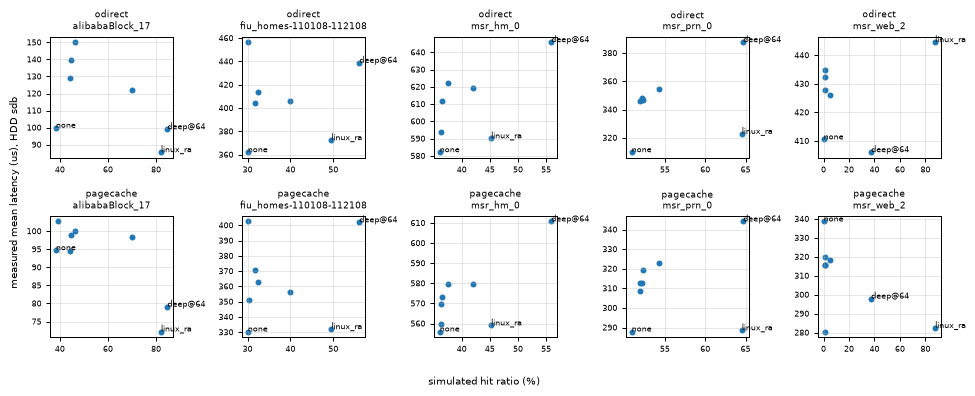

In [14]:
cells = hdd[(hdd["think"] == "closed") & hdd["usable"]].groupby(["backend", "trace"])
n = len(cells)
cols_n = min(5, n)
rows_n = -(-n // cols_n)
fig, axes = plt.subplots(rows_n, cols_n, figsize=(2.2 * cols_n, 2.2 * rows_n), squeeze=False)
for ax, ((backend, trace), part) in zip(axes.flat, cells):
    ax.scatter(100 * part["sim_hit_ratio"], part["lat_mean_us"], s=14)
    for _, r in part.iterrows():
        if r["mode"] in ("none", "deep@64", "linux_ra"):
            ax.annotate(r["mode"], (100 * r["sim_hit_ratio"], r["lat_mean_us"]), fontsize=6)
    ax.set_title(f"{backend}\n{trace}", fontsize=7)
    ax.tick_params(labelsize=6)
for ax in list(axes.flat)[n:]:
    ax.axis("off")
fig.supxlabel("simulated hit ratio (%)", fontsize=8)
fig.supylabel("measured mean latency (us), HDD sdb", fontsize=8)
fig.tight_layout()

### 4.3 SSD rows (secondary, flagged)

The SSD carries other tenants' I/O. Every SSD row shows `foreign_io_frac_max`;
a row above the 1% limit is flagged and not used by any decision
(`contended (not used)`).

In [15]:
ssd = summary[summary["device"] != "sdb"].copy()
ssd["flag"] = np.where(ssd["foreign_io_frac_max"] > decisions.FOREIGN_LIMIT,
                       "FLAGGED: foreign I/O > 1%", "")
ssd[["device", "backend", "think", "trace", "mode", "reps", "sim_hit_ratio", "lat_mean_us",
     "lat_mean_CI_us", "foreign_io_frac_max", "load_avg_max", "flag"]].set_index(
    ["device", "backend", "trace", "mode"])

think  reps  sim_hit_ratio  lat_mean_us lat_mean_CI_us  foreign_io_frac_max  load_avg_max                       flag
device backend   trace     mode                                                                                                                            
ssd    odirect   msr_hm_0  deep       closed     3         0.4208     100.2475      [96, 104]               0.0020        4.5571                           
                 msr_web_2 deep       closed     3         0.0476     499.8349     [498, 501]               0.0001        8.4399                           
                 msr_hm_0  guard      closed     3         0.3630     109.1687      [99, 119]               0.0005        9.1294                           
                 msr_web_2 guard      closed     3         0.0124     501.7471     [471, 533]               0.0002       13.5352                           
                 msr_hm_0  linux_ra   closed     3         0.4523     104.4181     [101, 107]               0.0020        8.5068                           
                 msr_web_2 linux_ra   closed     3         0.8760     468.8668     [457, 481]               0.0001       13.7017                           
                 msr_hm_0  none       closed     3         0.3610     106.8881     [104, 109]               0.0019       12.5503                           
                 msr_web_2 none       closed     3         0.0007     454.7527     [449, 460]               0.0004        6.9429                           
       pagecache msr_hm_0  deep       closed     3         0.4208      89.6303       [83, 97]               0.0006       11.8652                           
                 msr_web_2 deep       closed     3         0.0476     372.7296     [367, 378]               0.0001        8.1060                           
                 msr_hm_0  guard      closed     3         0.3630      97.0764       [96, 98]               0.0018        4.7163                           
                 msr_web_2 guard      closed     3         0.0124     374.3833     [360, 389]               0.0105       10.3560  FLAGGED: foreign I/O > 1%
                 msr_hm_0  kernel_ra  closed     3            NaN      87.3402       [84, 91]               0.0012        9.5762                           
                 msr_web_2 kernel_ra  closed     3            NaN     187.0775     [185, 189]               0.0002       11.2354                           
                 msr_hm_0  linux_ra   closed     3         0.4523      92.8991      [85, 101]               0.0006        4.4722                           
                 msr_web_2 linux_ra   closed     3         0.8760     249.3391     [240, 259]               0.0006        8.7036                           
                 msr_hm_0  none       closed     3         0.3610      97.5712       [96, 99]               0.0004        8.6382                           
                 msr_web_2 none       closed     3         0.0007     390.9217     [363, 419]               0.0001       12.0625

In [16]:
verdicts = decision_frame("realio", rules={"R1", "R6", "R3"})
print("R1/R6 verdict counts (mode - none, measured mean latency):")
display(verdicts[verdicts["rule"] != "R3"].groupby(["rule", "verdict"]).size().rename("cells")
        .to_frame())
verdicts[verdicts["rule"] == "R3"]

R1/R6 verdict counts (mode - none, measured mean latency):


cells
rule verdict                                  
R1   contended (not used)                    3
     lowers mean latency                    11
     no difference detected (3 repeats)     34
     raises mean latency                    42
R6   contended (not used)                    1
     lowers mean latency                     5
     no difference detected (3 repeats)      6
     raises mean latency                     2

,study,rule,scope,comparison,verdict,interval(s),note
104,realio,R3,all devices,Backend B parity with the simulator plan,held on all 150 odirect runs,,asserted per request; a divergence raises Cach...


## 5. E4 and E5: web prefetching in simulation

**Simulated** per-session browser-cache replay of RetailRocket split 3, every
choice frozen on split 2. Utility `U(c)` charges each issued prefetch an
assumed cost `c` in hit-equivalents; object sizes are equal and prefetches
complete instantly. Every comparison is against the best fixed depth *at the
same capacity*, against `fixed0` (no prefetch) and against transition top-1.
Sources: `results/web/comparisons.csv`, `decomposition.csv`,
`freshness.csv`, `seq_metrics.csv`; paper Sec. Web Results
(`sections/web_results.tex`), Tables `t5_web_decomposition`,
`t6_web_comparisons`, Figs. `f6_freshness`, `f8_utility_envelopes`.

### 5.1 The validated controller against the strongest fixed baseline

Per-capacity selection (W1), the logistic ranker, test split. Differences in
utility per view with session-bootstrap intervals.

In [17]:
comparisons = csv("web/comparisons.csv")
headline_web = comparisons[(comparisons["split"] == "test")
                           & (comparisons["selection"] == "per_capacity")
                           & (comparisons["scorer"] == "logistic")
                           & comparisons["adaptive_policy"].str.match(r"adaptive_\d")].copy()
for name in ("vs_best_fixed_same_cap", "vs_fixed0", "vs_transition_top1"):
    headline_web[name + "_CI"] = [ci(lo, hi, 1, 5) for lo, hi in
                                  zip(headline_web[name + "_lo"], headline_web[name + "_hi"])]
headline_web[["capacity", "cost", "adaptive_policy", "best_fixed_policy", "adaptive_utility",
              "best_fixed_utility", "vs_best_fixed_same_cap", "vs_best_fixed_same_cap_CI",
              "vs_fixed0_CI", "vs_transition_top1_CI", "adaptive_issued_per_view",
              "best_fixed_issued_per_view", "label"]].set_index(["capacity", "cost"])

adaptive_policy best_fixed_policy  adaptive_utility  best_fixed_utility  vs_best_fixed_same_cap vs_best_fixed_same_cap_CI         vs_fixed0_CI vs_transition_top1_CI  \
capacity cost                                                                                                                                                                          
2        0.0000    adaptive_0.1            fixed0            0.1057              0.1053                  0.0004        [0.00030, 0.00050]   [0.00030, 0.00050]    [0.01495, 0.01613]   
         0.0100    adaptive_0.1            fixed0            0.1056              0.1053                  0.0004        [0.00025, 0.00046]   [0.00025, 0.00046]    [0.02401, 0.02519]   
         0.0500    adaptive_0.2            fixed0            0.1055              0.1053                  0.0002        [0.00013, 0.00024]   [0.00013, 0.00024]    [0.06025, 0.06148]   
         0.2500    adaptive_0.2            fixed0            0.1053              0.1053                  0.0000       [-0.00002, 0.00008]  [-0.00002, 0.00008]    [0.24220, 0.24360]   
4        0.0000  adaptive_0.005            fixed2            0.1195              0.1214                 -0.0020      [-0.00220, -0.00168]   [0.00702, 0.00759]   [-0.00028, 0.00031]   
         0.0100   adaptive_0.02            fixed0            0.1141              0.1122                  0.0020        [0.00174, 0.00218]   [0.00174, 0.00218]    [0.00313, 0.00361]   
         0.0500    adaptive_0.1            fixed0            0.1126              0.1122                  0.0004        [0.00031, 0.00050]   [0.00031, 0.00050]    [0.03635, 0.03694]   
         0.2500    adaptive_0.2            fixed0            0.1122              0.1122                  0.0001        [0.00001, 0.00010]   [0.00001, 0.00010]    [0.20994, 0.21079]   
8        0.0000  adaptive_0.002            fixed4            0.1308              0.1317                 -0.0009      [-0.00121, -0.00065]   [0.01591, 0.01661]    [0.00594, 0.00665]   
         0.0100   adaptive_0.01            fixed1            0.1190              0.1154                  0.0036        [0.00331, 0.00385]   [0.00413, 0.00477]    [0.00270, 0.00320]   
         0.0500   adaptive_0.05            fixed0            0.1150              0.1145                  0.0005        [0.00036, 0.00063]   [0.00036, 0.00063]    [0.03269, 0.03326]   
         0.2500    adaptive_0.2            fixed0            0.1146              0.1145                  0.0001        [0.00001, 0.00011]   [0.00001, 0.00011]    [0.20187, 0.20281]   
16       0.0000  adaptive_0.002            fixed8            0.1406              0.1395                  0.0011        [0.00095, 0.00118]   [0.02472, 0.02571]    [0.01417, 0.01491]   
         0.0100   adaptive_0.01            fixed1            0.1223              0.1170                  0.0053        [0.00500, 0.00551]   [0.00651, 0.00725]    [0.00433, 0.00483]   
         0.0500   adaptive_0.05            fixed0            0.1159              0.1154                  0.0006        [0.00042, 0.00070]   [0.00042, 0.00070]    [0.03152, 0.03214]   
         0.2500    adaptive_0.2            fixed0            0.1154              0.1154                  0.0001        [0.00002, 0.00011]   [0.00002, 0.00011]    [0.19860, 0.19963]   
32       0.0000  adaptive_0.002            fixed8            0.1437              0.1437                  0.0000       [-0.00007, 0.00009]   [0.02746, 0.02855]    [0.01675, 0.01755]   
         0.0100   adaptive_0.01            fixed1            0.1233              0.1175                  0.0058        [0.00555, 0.00606]   [0.00727, 0.00806]    [0.00487, 0.00537]   
         0.0500   adaptive_0.05            fixed0            0.1162              0.1156                  0.0006        [0.00044, 0.00073]   [0.00044, 0.00073]    [0.03109, 0.03171]   
         0.2500    adaptive_0.2            fixed0            0.1157              0.1156                  0.0001        [0.00002, 0.00011]   [0.00002, 0.

In [18]:
decision_frame("web", rules={"W1", "W2", "rule 1"})

,study,rule,scope,comparison,verdict,interval(s),note
0,web,W1,"cap 8, c = 0.01, logistic","adaptive_0.01 - fixed1, U(0.01)",A better,"0.36 pp [0.33, 0.38]",
1,web,W2,"cap 8, c = 0.01, logistic","adaptive_0.01 - fixed0, U(0.01)",A better,"0.44 pp [0.41, 0.48]",
2,web,rule 1,"cap 8, c = 0.01, logistic",controller claim,the adaptive controller beats fixed prefetching,,
3,web,W1,"cap 32, c = 0.01, logistic","adaptive_0.01 - fixed1, U(0.01)",A better,"0.58 pp [0.55, 0.61]",
4,web,W2,"cap 32, c = 0.01, logistic","adaptive_0.01 - fixed0, U(0.01)",A better,"0.77 pp [0.73, 0.81]",
5,web,rule 1,"cap 32, c = 0.01, logistic",controller claim,the adaptive controller beats fixed prefetching,,


### 5.2 Which lever moves the result: the decomposition

Each lever changes one thing against a baseline (ranker, freshness of the
transition counts, depth, the controller, the feedback gate, cache scope, the
GRU sequence model). The verdict column uses the web rule's three wordings
(`decisions.web_verdict`); rule 2 orders the levers by their absolute
hit-ratio intervals and rule 3 states the feedback-gate claim.

In [19]:
decomposition = csv("web/decomposition.csv")
decomposition["CI"] = [ci(lo, hi, 1, 5) for lo, hi in
                       zip(decomposition["ci_lo"], decomposition["ci_hi"])]
decomposition["verdict"] = [decisions.web_verdict(lo, hi) for lo, hi in
                            zip(decomposition["ci_lo"], decomposition["ci_hi"])]
decomposition[["lever", "policy", "scorer", "baseline", "baseline_scorer", "capacity", "metric",
               "cost", "estimate", "CI", "verdict", "sessions"]]

,lever,policy,scorer,baseline,baseline_scorer,capacity,metric,cost,estimate,CI,verdict,sessions
0,ranker,fixed1,trans_s0,fixed1,logistic,8.0000,hit_ratio,0.0000,0.0007,"[0.00059, 0.00089]",A better,364364
1,ranker,fixed1,trans_s0,fixed1,logistic,8.0000,utility_per_view,0.0100,0.0006,"[0.00047, 0.00077]",A better,364364
2,freshness,fixed4,trans_online,fixed4,logistic,8.0000,hit_ratio,0.0000,0.0152,"[0.01487, 0.01560]",A better,364364
3,freshness,fixed4,trans_online,fixed4,logistic,8.0000,utility_per_view,0.0100,0.0148,"[0.01449, 0.01522]",A better,364364
4,depth,fixed4,logistic,fixed1,logistic,8.0000,hit_ratio,0.0000,0.0080,"[0.00765, 0.00827]",A better,364364
5,depth,fixed4,logistic,fixed1,logistic,8.0000,utility_per_view,0.0100,-0.0184,"[-0.01871, -0.01809]",A worse,364364
6,controller,adaptive_0.01,logistic,fixed1,logistic,8.0000,hit_ratio,0.0000,0.0026,"[0.00229, 0.00281]",A better,364364
7,controller,adaptive_0.01,logistic,fixed1,logistic,8.0000,utility_per_view,0.0100,0.0036,"[0.00331, 0.00385]",A better,364364
8,controller,adaptive_ca_0.01,logistic,fixed1,logistic,8.0000,hit_ratio,0.0000,0.0027,"[0.00246, 0.00292]",A better,364364
9,controller,adaptive_ca_0.01,logistic,fixed1,logistic,8.0000,utility_per_view,0.0100,0.0038,"[0.00359, 0.00409]",A better,364364


In [20]:
decision_frame("web", rules={"rule 2", "rule 3"})

,study,rule,scope,comparison,verdict,interval(s),note
0,web,rule 2,"cap 8, hit ratio",which lever moves hit ratio least,the predictor is not called the smallest lever,"|ranker|: -- [0.06, 0.09]; |sequence_model|: -...",ranker < depth; ranker < freshness; sequence_m...
1,web,rule 3,"cap 8, c = 0.01",feedback gate claim,not described as improving on the adaptive con...,,


### 5.3 Freshness: coverage of the next view by the transition index

The share of eligible next-view pairs whose target is in the top-k
transitions of the source, for a frozen index (split 0, splits 0-1 or 0-2)
and the causal online index. Source: `results/web/freshness.csv`; paper
Fig. `f6_freshness`.

k                        1      2      4      8     20    all
split      index                                             
validation split0   0.0366 0.0569 0.0801 0.0999 0.1175 0.1239
           split01  0.0463 0.0721 0.1021 0.1294 0.1555 0.1680
           online   0.0631 0.0975 0.1369 0.1734 0.2067 0.2236
test       split0   0.0333 0.0512 0.0729 0.0908 0.1059 0.1109
           online   0.0633 0.0974 0.1374 0.1753 0.2108 0.2312
           split012 0.0495 0.0770 0.1089 0.1399 0.1687 0.1841

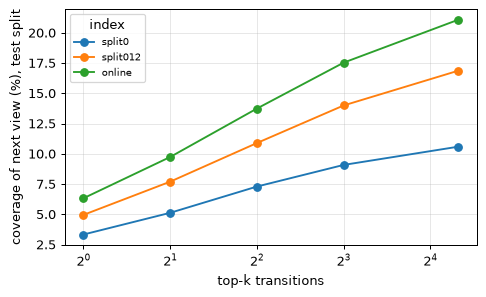

In [21]:
freshness = csv("web/freshness.csv")
freshness["k"] = freshness["k"].map(lambda k: "all" if pd.isna(k) else str(int(k)))
display(freshness.pivot_table(index=["split", "index"], columns="k", values="coverage",
                              sort=False)[["1", "2", "4", "8", "20", "all"]])
fig, ax = plt.subplots(figsize=(5.5, 3.4))
test = freshness[(freshness["split"] == "test") & (freshness["k"] != "all")]
for index, part in test.groupby("index", sort=False):
    ax.plot(part["k"].astype(int), 100 * part["coverage"], marker="o", label=index)
ax.set_xscale("log", base=2)
ax.set_xlabel("top-k transitions")
ax.set_ylabel("coverage of next view (%), test split")
ax.legend(title="index", fontsize=8)
fig.tight_layout()

### 5.4 The GRU sequence model

The GRU is scored on the final protocol (split 3) for each seed; it never
ranks an item already in the window, so it is compared on the `novel_*`
columns. W8 compares it with online transition counts at the same depth.
Source: `results/web/seq_metrics.csv`.

In [22]:
seq = csv("web/seq_metrics.csv")
final = seq[(seq["protocol"] == "final") & (seq["status"] == "ok")]
ranking = final.groupby("seed")[["hit_at_1", "mrr_at_8", "novel_hit_at_1",
                                 "novel_recall_at_8"]].first()
display(ranking)
cap8 = final[(final["capacity"] == 8) & (final["cost"] == 0.01)]
display(cap8.groupby("policy")[["hit_ratio", "issued_per_view", "utility"]]
        .agg(["mean", "min", "max"]).round(4))
decision_frame("web", rules={"W8"})

,hit_at_1,mrr_at_8,novel_hit_at_1,novel_recall_at_8
seed,,,,
0,0.0358,0.0583,0.0563,0.1726
1,0.0359,0.0583,0.0563,0.1720
2,0.0363,0.0586,0.0571,0.1721
3,0.0355,0.0577,0.0557,0.1702
4,0.0357,0.0582,0.0560,0.1726


hit_ratio               issued_per_view               utility              
                       mean    min    max            mean    min    max    mean    min    max
policy                                                                                       
adaptive_0.002       0.1370 0.1368 0.1373          3.6768 3.6006 3.7543  0.1002 0.0997 0.1010
adaptive_0.005       0.1369 0.1366 0.1374          2.6381 2.5843 2.7173  0.1105 0.1101 0.1109
adaptive_0.01        0.1356 0.1353 0.1361          1.7735 1.7270 1.8477  0.1178 0.1176 0.1181
adaptive_0.02        0.1322 0.1318 0.1328          0.9928 0.9573 1.0531  0.1223 0.1221 0.1225
adaptive_0.05        0.1258 0.1255 0.1262          0.3957 0.3805 0.4286  0.1218 0.1217 0.1219
adaptive_0.1         0.1210 0.1208 0.1214          0.1819 0.1733 0.2004  0.1192 0.1190 0.1194
adaptive_0.2         0.1178 0.1177 0.1179          0.0778 0.0730 0.0859  0.1170 0.1170 0.1171
adaptive_ca_0.002    0.1362 0.1359 0.1365          3.7354 3.6548 3.8154  0.0989 0.0984 0.0997
adaptive_ca_0.005    0.1366 0.1362 0.1373          2.6410 2.5851 2.7194  0.1102 0.1097 0.1107
adaptive_ca_0.01     0.1355 0.1352 0.1360          1.7533 1.7065 1.8263  0.1180 0.1177 0.1182
adaptive_ca_0.02     0.1323 0.1319 0.1329          0.9750 0.9409 1.0352  0.1225 0.1223 0.1227
adaptive_ca_0.05     0.1258 0.1256 0.1262          0.3945 0.3793 0.4276  0.1218 0.1218 0.1219
adaptive_ca_0.1      0.1210 0.1208 0.1214          0.1819 0.1733 0.2005  0.1192 0.1190 0.1194
adaptive_ca_0.2      0.1178 0.1177 0.1179          0.0778 0.0730 0.0859  0.1170 0.1170 0.1171
fixed0               0.1145 0.1145 0.1145          0.0000 0.0000 0.0000  0.1145 0.1145 0.1145
fixed1               0.1275 0.1274 0.1276          0.9058 0.9027 0.9088  0.1185 0.1184 0.1185
fixed2               0.1335 0.1334 0.1336          1.8014 1.7942 1.8067  0.1155 0.1153 0.1156
fixed4               0.1390 0.1389 0.1391          3.6310 3.6258 3.6370  0.1027 0.1026 0.1029
fixed8               0.1335 0.1333 0.1338          7.6794 7.6740 7.6840  0.0567 0.0565 0.0571
gate_0.01            0.1325 0.1324 0.1327          1.0906 1.0761 1.1105  0.1216 0.1214 0.1216
gate_0.02            0.1313 0.1311 0.1317          0.9165 0.8992 0.9484  0.1221 0.1220 0.1222
gate_0.05            0.1276 0.1273 0.1281          0.5842 0.5642 0.6237  0.1217 0.1217 0.1219
gate_0.1             0.1229 0.1226 0.1234          0.3253 0.3110 0.3553  0.1196 0.1195 0.1198

,study,rule,scope,comparison,verdict,interval(s),note
0,web,W8,cap 8,sequence_model: fixed4@seq - fixed4@trans_onli...,A worse,"-0.79 pp [-0.83, -0.76]",364364 sessions
1,web,W8,cap 8,sequence_model: fixed4@seq - fixed4@trans_onli...,A worse,"-0.92 pp [-0.96, -0.88]",364364 sessions


## 6. E6: live HTTP replay (measured)

A real HTTP client replays split-3 sessions against an origin server over
loopback with an **emulated** network (RTT, bandwidth) and **assumed**
object sizes, from a store on the HDD or the shared SSD. A pass is valid only
if every lag p99 is at most 2 ms with no parity mismatch and no connection
error; an SSD pass above the 1% foreign-I/O limit is flagged and not cited
(`genlib.live_citable`). Sources: `results/live/live_metrics.csv`,
`live_parity.csv`; paper Sec. Live HTTP Results (`sections/live_results.tex`),
Tables `t7_live`, `t7b_live_ablation`, Fig. `f7_live_saved_vs_bytes`.

In [23]:
live_rows = TREE.rows("live/live_metrics.csv")
citable_ids = {id(r) for r in genlib.live_citable(live_rows)}
live = pd.DataFrame(live_rows)
live["citable"] = [id(r) in citable_ids for r in live_rows]
print(f"passes: {len(live)}; valid: {int(live['valid'].sum())}; "
      f"citable (valid and not flagged): {int(live['citable'].sum())}")
flagged = live[~live["citable"]]
if len(flagged):
    print("not cited (flagged or invalid):")
    display(flagged[["experiment", "store", "rep", "policy", "valid", "foreign_io_frac"]])

passes: 42; valid: 42; citable (valid and not flagged): 37
not cited (flagged or invalid):


,experiment,store,rep,policy,valid,foreign_io_frac
2,headline,ssd,0,fixed8,True,0.0746
3,headline,ssd,0,adaptive_0.01,True,0.8201
4,headline,ssd,0,feedback_0.01_eps0.005,True,0.1281
5,headline,ssd,0,adaptive_0.1@trans_online,True,0.0393
8,headline,ssd,1,adaptive_0.01,True,0.0150


In [24]:
cited = live[live["citable"] & (live["experiment"] == "headline")].copy()
cited["saved_ms"] = -cited["delta_vs_base_ms"]
per_policy = cited.groupby(["store", "policy"]).agg(
    reps=("rep", "nunique"), hit_ratio=("hit_ratio", "mean"),
    mean_wait_ms=("mean_wait_ms", "mean"), saved_ms=("saved_ms", "mean"),
    model_ideal_saved_ms=("ideal_delta_vs_base_ms", lambda s: -s.mean()),
    bytes_vs_base=("bytes_vs_base", "mean"), kb_per_view=("kb_per_view", "mean"))
envelope = {}
for (store, policy), part in cited.groupby(["store", "policy"]):
    saved = genlib.live_saved(part.to_dict("records"))
    envelope[(store, policy)] = "--" if saved is None else ci(saved[1], saved[2], 1, 2)
per_policy["saved_CI_envelope_ms"] = pd.Series(envelope)
per_policy

reps  hit_ratio  mean_wait_ms  saved_ms  model_ideal_saved_ms  bytes_vs_base  kb_per_view saved_CI_envelope_ms
store policy                                                                                                                                   
hdd   adaptive_0.01                 3     0.2733      109.1347    4.9773                3.1885         2.1874     174.3590         [4.14, 5.89]
      adaptive_0.1@trans_online     3     0.2917      105.8381    8.2739                6.1184         2.1968     175.1012         [7.09, 9.73]
      feedback_0.01_eps0.005        3     0.2788      107.1250    6.9870                4.3407         2.9995     239.0870         [5.95, 8.19]
      fixed0                        3     0.2486      114.1120    0.0000               -0.0000         1.0000      79.7090       [-0.00, -0.00]
      fixed4                        3     0.2842      105.9354    8.1766                5.0929         6.7082     534.7054         [6.91, 9.71]
      fixed8                        3     0.2740      106.8784    7.2336                3.3170        14.9110    1188.5437         [6.33, 8.14]
ssd   adaptive_0.01                 1     0.2733      101.7613    3.3913                3.1885         2.1874     174.3590         [2.75, 4.13]
      adaptive_0.1@trans_online     2     0.2917       98.7902    6.3621                6.1184         2.1968     175.1012         [5.34, 7.51]
      feedback_0.01_eps0.005        2     0.2788      100.5755    4.5768                4.3407         2.9995     239.0870         [3.72, 5.67]
      fixed0                        3     0.2486      105.1580    0.0000               -0.0000         1.0000      79.7090       [-0.00, -0.00]
      fixed4                        3     0.2842       99.7603    5.3977                5.0929         6.7082     534.7054         [4.45, 6.53]
      fixed8                        2     0.2740      101.7642    3.3881                3.3170        14.9110    1188.5437         [2.64, 4.14]

In [25]:
parity = csv("live/live_parity.csv")
totals = parity.groupby("experiment")[["sessions", "sim_hits", "live_hits", "sim_issued",
                                       "live_issued", "mismatched_sessions"]].sum()
totals["hits_equal"] = totals["sim_hits"] == totals["live_hits"]
totals["issued_equal"] = totals["sim_issued"] == totals["live_issued"]
display(totals)
decision_frame("live")

,sessions,sim_hits,live_hits,sim_issued,live_issued,mismatched_sessions,hits_equal,issued_equal
experiment,,,,,,,,
fifo,6000,5394,5394,70873,70873,0,True,True
headline,72000,66210,66210,559764,559764,0,True,True
hint,6000,4986,4986,0,0,0,True,True


,study,rule,scope,comparison,verdict,interval(s),note
0,live,H1,all passes,live counters vs simulator,no mismatch,,42 pass-policy rows
1,live,H2,hdd store,"adaptive_0.01 - fixed0, mean wait",lowers the mean wait,"rep 0: -4.96 ms [-5.77, -4.25]; rep 1: -4.89 m...",3 citable repetitions
2,live,H3,hdd store,adaptive_0.01: measured vs model-ideal delta,the instant-prefetch model understates the ben...,"rep 0: -4.96 ms [-5.77, -4.25]; rep 1: -4.89 m...",3 citable repetitions
3,live,H2,hdd store,"adaptive_0.1@trans_online - fixed0, mean wait",lowers the mean wait,"rep 0: -8.13 ms [-9.28, -7.09]; rep 1: -8.14 m...",3 citable repetitions
4,live,H3,hdd store,adaptive_0.1@trans_online: measured vs model-i...,the instant-prefetch model understates the ben...,"rep 0: -8.13 ms [-9.28, -7.09]; rep 1: -8.14 m...",3 citable repetitions
5,live,H2,hdd store,"feedback_0.01_eps0.005 - fixed0, mean wait",lowers the mean wait,"rep 0: -6.86 ms [-7.92, -5.95]; rep 1: -6.99 m...",3 citable repetitions
6,live,H3,hdd store,feedback_0.01_eps0.005: measured vs model-idea...,the instant-prefetch model understates the ben...,"rep 0: -6.86 ms [-7.92, -5.95]; rep 1: -6.99 m...",3 citable repetitions
7,live,H2,hdd store,"fixed4 - fixed0, mean wait",lowers the mean wait,"rep 0: -8.05 ms [-9.20, -7.03]; rep 1: -7.95 m...",3 citable repetitions
8,live,H3,hdd store,fixed4: measured vs model-ideal delta,the instant-prefetch model understates the ben...,"rep 0: -8.05 ms [-9.20, -7.03]; rep 1: -7.95 m...",3 citable repetitions
9,live,H2,hdd store,"fixed8 - fixed0, mean wait",lowers the mean wait,"rep 0: -7.25 ms [-8.09, -6.43]; rep 1: -7.13 m...",3 citable repetitions


## 7. Every pre-registered decision

All verdicts computed by `paper/decisions.py` (the paper's Table
`t9_decisions`, appendix "The Pre-Registered Decisions"): first the count of
each verdict per study and rule, then the full list.

In [26]:
everything = decision_frame()
display(everything.groupby(["study", "rule", "verdict"]).size().rename("count").to_frame())
everything

count
study        rule    verdict                                                  
classifier   CLF0    better                                                 26
                     no difference detected                                 86
                     worse                                                  42
             CLF1    better                                                  3
                     no difference detected                                 17
                     worse                                                  16
             CLF2    better                                                 14
                     no difference detected                                 19
                     worse                                                   1
             CLF3    increases device I/Os                                  34
                     reduces device I/Os                                     2
             CLF4    moves more blocks                                      36
             claim   no routed classifier beats read-ahead                   2
                     supported for gnb, lda, logreg, knn, svm_linear...      1
                     supported for rf                                        1
disk         C3      prefix-dependent                                        1
                     robust                                                  6
             C4      cap-insensitive                                         7
             E2      worse                                                   2
             P1      worse                                                   2
             P2      paired interval only; not robust to corpus clus...      1
                     worse                                                   3
             P3      better                                                  6
             P4      better                                                  6
             P5      increases device I/Os                                  20
                     no difference detected                                  3
                     paired interval only; not robust to corpus clus...      1
                     reduces device I/Os                                     6
             P6      moves more blocks                                      30
             levers  the predictor is not the smallest lever                 2
hindsight    D       increases device I/Os                                  21
                     moves more blocks                                      38
                     no difference detected                                 17
                     no difference detected (paired interval only; n...      1
                     reduces device I/Os                                     7
             H1      no difference detected                                  1
                     worse                                                   1
             H2      better                                                  2
             H3      no difference detected                                  2
             H4      no difference detected                                  1
                     no difference detected (paired interval only; n...      1
             H5      better                                                  2
             H6      worse                                                   2
             H7      better                                                  2
                     no difference detected                                  3
                     worse                                                   1
             R       better                                                  3
                     no difference detected (paired interval only; n...      3
             S1      better                                                  6
             S2      no difference detected 

,study,rule,scope,comparison,verdict,interval(s),note
0,disk,P1,1 MiB,"adaptive - sequential, hit ratio",worse,"paired: -0.94 pp [-1.31, -0.58]; cluster: -0.8...",n = 56 traces
1,disk,P1,64 MiB,"adaptive - sequential, hit ratio",worse,"paired: -1.21 pp [-1.52, -0.92]; cluster: -1.0...",n = 56 traces
2,disk,P2,1 MiB,"guard - sequential, hit ratio",paired interval only; not robust to corpus clu...,"paired: -0.46 pp [-0.73, -0.14]; cluster: -0.4...",n = 56 traces
3,disk,P2,64 MiB,"guard - sequential, hit ratio",worse,"paired: -0.22 pp [-0.30, -0.16]; cluster: -0.2...",n = 56 traces
4,disk,P2,"1 MiB, break-even cost model","guard - sequential, hit ratio",worse,"paired: -1.65 pp [-2.61, -0.96]; cluster: -1.6...",n = 56 traces
...,...,...,...,...,...,...,...
1040,msrc_samples,M2,"web_1, lofo_real","mlp - route_window, balanced accuracy",worse,"-27.83 pp [-28.53, -27.15]",n = 5027 windows (serially correlated; window ...
1041,msrc_samples,M1,"web_3, lofo_real","mlp - gnb, balanced accuracy",worse,"-30.48 pp [-32.45, -28.57]",n = 980 windows (serially correlated; window b...
1042,msrc_samples,M2,"web_3, lofo_real","mlp - route_window, balanced accuracy",worse,"-23.98 pp [-26.03, -22.03]",n = 980 windows (serially correlated; window b...
1043,msrc_samples,M1,"pooled, lofo_real","mlp - gnb, balanced accuracy",worse,"-41.50 pp [-41.90, -41.03]",n = 18641 windows (serially correlated; window...


## 8. Classifier study (E7 and later)

These studies were added after E1-E6: the classifier zoo and router
benchmark (`results/classifier`), the hindsight router (`results/hindsight`),
the web rankers (`results/web_rankers`) and the MSRC light-sample transfer
check (`results/msrc_samples`). Each was pre-registered before it ran. The
cell below discovers whatever has landed: for each study it prints the
decision-rule section of its `PREREGISTERED.md`, lists its results files,
checks their provenance and shows each table (any `verdict` column in
full). A study whose results are not there yet prints how to produce them.
Classifier accuracy is on synthetic windows only; real traces have no
workload labels.

In [27]:
import re

LATER_STUDIES = (("classifier", "classifier", "classifier zoo and router benchmark"),
                 ("hindsight", "hindsight", "hindsight router"),
                 ("web_rankers", "web_rankers", "web rankers"),
                 ("msrc_samples", "msrc", "MSRC light-sample transfer check"))


def rule_sections(text):
    """The '## ...' sections of a PREREGISTERED.md that state decision rules."""
    parts = re.split(r"(?m)^(?=## )", text)
    keep = [p for p in parts if p.startswith("## ")
            and re.search(r"decision|comparison|rule", p.splitlines()[0], re.I)]
    return "\n".join(keep).strip()


for directory, study, title in LATER_STUDIES:
    root = RESULTS / directory
    print("=" * 78)
    print(f"{title}: results/{directory}")
    if not root.is_dir():
        print(f"not yet generated: run reproduce.py {study}")
        continue
    prereg = root / "PREREGISTERED.md"
    if prereg.is_file():
        text = prereg.read_text(encoding="utf-8")
        print(text.splitlines()[0])
        rules = rule_sections(text)
        if rules:
            print(rules)
    tables = sorted(p for p in root.rglob("*") if p.suffix in (".csv", ".json")
                    and p.name != "provenance.json")
    if not tables:
        print(f"not yet generated: run reproduce.py {study}")
        continue
    if (root / "provenance.json").is_file():
        problems = provenance.verify_provenance(root)
        print("provenance: " + ("all files match" if not problems else "; ".join(problems)))
    else:
        print("provenance: no provenance.json (not a complete reproduce run)")
    for path in tables:
        print(f"-- {path.relative_to(RESULTS)}")
        if path.suffix == ".csv":
            frame = pd.read_csv(path)
            verdict_columns = [c for c in frame.columns if "verdict" in c.lower()]
            if verdict_columns:
                display(frame)
            else:
                print(f"{len(frame)} rows; the first 25:")
                display(frame.head(25))
        else:
            payload = json.loads(path.read_text(encoding="utf-8"))
            print(json.dumps(payload, indent=1, sort_keys=True)[:3000])

classifier zoo and router benchmark: results/classifier
# Classifier zoo and router benchmark (track CLF): pre-registered comparisons
## 4. Decision rules

- **Paired bootstrap** over units (seed pairs in Part 1, traces in Part 2):
  10,000 resamples, seed 42, 95% percentile interval.
- **Cluster bootstrap** (Part 2 only): corpora, then traces within each
  drawn corpus, twin families down-weighted to total weight 1
  (`stats.cluster_bootstrap` with `stats.twin_weights(corpora.TWIN_GROUPS)`),
  10,000 resamples, seed 42.
- "**better**" iff the interval lies entirely on the better side (Part 2:
  both the paired and the cluster interval); "**worse**" iff entirely on the
  worse side (Part 2: both); otherwise "**no difference detected**", stated
  with the interval(s). For a ratio the null is 1 and lower device work is
  better.
- "A tuned classifier makes the router better" is written only if some
  family is **better** than `gnb_online` on hit ratio at a capacity **and**
  its device-I

,capacity,metric,statistic,policy,baseline,n,estimate,ci_lo,ci_hi,cluster_estimate,cluster_ci_lo,cluster_ci_hi,verdict,wins,losses,ties,reps,seed
0,2048,hit_ratio,difference,gnb_online,sequential,19,-0.0025,-0.0086,0.0055,-0.0025,-0.0097,0.0147,no difference detected,4,15,0,10000,42
1,2048,device_ios,ratio,gnb_online,none,19,1.1445,1.0216,1.3212,1.1445,1.0131,1.5806,worse,2,16,1,10000,42
2,2048,blocks_moved,ratio,gnb_online,none,19,1.0227,1.0092,1.0406,1.0227,1.0081,1.0592,worse,0,19,0,10000,42
3,2048,hit_ratio,difference,qda_online,sequential,19,-0.0056,-0.0136,0.0019,-0.0056,-0.0148,0.0085,no difference detected,4,15,0,10000,42
4,2048,hit_ratio,difference,qda_online,gnb_online,19,-0.0031,-0.0092,0.0013,-0.0031,-0.0119,0.0018,no difference detected,10,9,0,10000,42
5,2048,device_ios,ratio,qda_online,none,19,1.0897,1.0269,1.1786,1.0897,1.0225,1.2960,worse,0,18,1,10000,42
6,2048,blocks_moved,ratio,qda_online,none,19,1.0369,1.0196,1.0601,1.0369,1.0173,1.0851,worse,0,19,0,10000,42
7,2048,hit_ratio,difference,gnb,sequential,19,-0.0028,-0.0090,0.0045,-0.0028,-0.0096,0.0124,no difference detected,4,15,0,10000,42
8,2048,hit_ratio,difference,gnb,gnb_online,19,-0.0003,-0.0034,0.0022,-0.0003,-0.0050,0.0027,no difference detected,12,7,0,10000,42
9,2048,device_ios,ratio,gnb,none,19,1.1602,1.0311,1.3477,1.1602,1.0241,1.6164,worse,0,18,1,10000,42


-- classifier/router_runs.csv
760 rows; the first 25:


,trace,corpus,capacity,policy,source,label_key,gnb_label_key,requests,windows,hit_ratio,precision,total_prefetches,useful_prefetches,device_ios,blocks_moved,policy_switches,share_sequential,share_strided,share_random,share_mixed,agreement_with_gnb,age_table_evictions,wall_s,load_avg
0,msr_hm_0,msr,2048,gnb_online,replayed_labels,a596b456c9fdf900,a596b456c9fdf900,1000000,31250.0000,0.3431,0.3429,78978,27078,475388,11403167,3606,0.1829,0.7750,0.0226,0.0196,1.0000,0.0000,21.6870,91.7900
1,msr_hm_0,msr,2048,qda_online,replayed_labels,f8637359c802bb9c,a596b456c9fdf900,1000000,31250.0000,0.3460,0.2430,424417,103141,499256,11698306,1014,0.0053,0.0087,0.0153,0.9707,0.0444,0.0000,26.5320,91.7900
2,msr_hm_0,msr,2048,gnb,replayed_labels,3ed46ecc1c667d4c,a596b456c9fdf900,1000000,31250.0000,0.3452,0.2756,301450,83092,502941,11589674,11013,0.1814,0.3186,0.0187,0.4813,0.5096,0.0000,24.0950,91.7900
3,msr_hm_0,msr,2048,lda,replayed_labels,a34ec4659393575a,a596b456c9fdf900,1000000,31250.0000,0.3468,0.2546,483306,123055,505154,11743498,6514,0.1814,0.0841,0.0236,0.7108,0.1147,0.0000,19.4060,91.7900
4,msr_hm_0,msr,2048,qda,replayed_labels,fb6cc94fe1c08cd3,a596b456c9fdf900,1000000,31250.0000,0.3441,0.2339,282961,66191,504122,11589664,7658,0.0258,0.1759,0.1896,0.6088,0.0786,0.0000,22.1830,92.5200
5,msr_hm_0,msr,2048,logreg,replayed_labels,499071ec1c43e194,a596b456c9fdf900,1000000,31250.0000,0.3462,0.2498,442789,110610,501297,11712612,3373,0.1593,0.0007,0.0256,0.8144,0.1926,0.0000,26.9980,92.5200
6,msr_hm_0,msr,2048,knn,replayed_labels,37b0795291414bf7,a596b456c9fdf900,1000000,31250.0000,0.3446,0.2500,287672,71914,499562,11586689,12793,0.3793,0.5678,0.0209,0.0320,0.6088,0.0000,23.4350,92.2400
7,msr_hm_0,msr,2048,svm_linear,replayed_labels,13bfedd131a3a019,a596b456c9fdf900,1000000,31250.0000,0.3464,0.2541,450490,114460,502031,11717499,3800,0.1957,0.0011,0.0312,0.7719,0.2155,0.0000,20.6100,93.2600
8,msr_hm_0,msr,2048,svm_rbf,replayed_labels,0de3230f4ae9d30d,a596b456c9fdf900,1000000,31250.0000,0.3453,0.2390,398076,95152,504572,11684183,6643,0.1393,0.1650,0.0178,0.6780,0.2027,0.0000,20.9630,93.2600
9,msr_hm_0,msr,2048,cart,replayed_labels,908bd2071ec184f0,a596b456c9fdf900,1000000,31250.0000,0.3444,0.3559,155026,55174,482707,11455959,7766,0.1817,0.0009,0.6423,0.1750,0.2018,0.0000,20.6730,93.2600


-- classifier/router_summary.csv
40 rows; the first 25:


...

,protocol,classifier,label_rule,trace,status,train_on,n_windows,n_seq,small_n,accuracy,accuracy_lo,accuracy_hi,balanced_accuracy,balanced_accuracy_lo,balanced_accuracy_hi,macro_f1,macro_f1_lo,macro_f1_hi,seq_precision,seq_recall,predicted_seq,predicted_classes,above_chance,reps,seed
0,shipped_synthetic,gnb,majority,rsrch_1,ok,"make_model(seed=42), synthetic",430,0,True,0.9372,0.9140,0.9581,NaN,NaN,NaN,NaN,NaN,NaN,0.0000,NaN,27.0000,"{""mixed"":50,""random"":6,""sequential"":27,""stride...",NaN,2000,42
1,shipped_synthetic,gnb,majority,rsrch_2,ok,"make_model(seed=42), synthetic",6487,0,True,0.8699,0.8617,0.8781,NaN,NaN,NaN,NaN,NaN,NaN,0.0000,NaN,844.0000,"{""mixed"":1875,""random"":1,""sequential"":844,""str...",NaN,2000,42
2,shipped_synthetic,gnb,majority,wdev_1,ok,"make_model(seed=42), synthetic",32,0,True,1.0000,1.0000,1.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0000,"{""strided"":32}",NaN,2000,42
3,shipped_synthetic,gnb,majority,wdev_2,ok,"make_model(seed=42), synthetic",5664,1,True,0.9995,0.9988,1.0000,0.9997,0.9994,1.0000,0.6999,0.6247,1.0000,0.2500,1.0000,4.0000,"{""mixed"":109,""random"":4,""sequential"":4,""stride...",NaN,2000,42
4,shipped_synthetic,gnb,majority,wdev_3,ok,"make_model(seed=42), synthetic",21,0,True,1.0000,1.0000,1.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0000,"{""strided"":21}",NaN,2000,42
5,shipped_synthetic,gnb,majority,web_1,ok,"make_model(seed=42), synthetic",5027,74,False,0.6240,0.6107,0.6370,0.8092,0.8024,0.8158,0.4184,0.4080,0.4281,0.0377,1.0000,1964.0000,"{""mixed"":250,""random"":41,""sequential"":1964,""st...",True,2000,42
6,shipped_synthetic,gnb,majority,web_3,ok,"make_model(seed=42), synthetic",980,340,False,0.7459,0.7184,0.7745,0.8048,0.7857,0.8245,0.7452,0.7176,0.7732,0.5775,0.9971,587.0000,"{""mixed"":34,""random"":2,""sequential"":587,""strid...",True,2000,42
7,shipped_synthetic,gnb,majority,pooled,ok,"make_model(seed=42), synthetic",18641,415,False,0.8384,0.8329,0.8434,0.9162,0.9123,0.9195,0.5627,0.5534,0.5721,0.1208,0.9976,3426.0000,"{""mixed"":2318,""random"":54,""sequential"":3426,""s...",True,2000,42
8,shipped_synthetic,qda,majority,rsrch_1,ok,"make_model(seed=42), synthetic",430,0,True,0.9814,0.9674,0.9930,NaN,NaN,NaN,NaN,NaN,NaN,0.0000,NaN,8.0000,"{""mixed"":418,""random"":1,""sequential"":8,""stride...",NaN,2000,42
9,shipped_synthetic,qda,majority,rsrch_2,ok,"make_model(seed=42), synthetic",6487,0,True,1.0000,1.0000,1.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0000,"{""mixed"":6316,""random"":142,""strided"":29}",NaN,2000,42


-- msrc_samples/replay.csv
168 rows; the first 25:


,trace,view,mode,latency_model,status,requests,read_requests,read_blocks,read_hits,hit_ratio,hit_ratio_delta_vs_none,prefetches,useful_prefetches,precision,device_ios,device_ios_ratio_vs_none,blocks_moved,blocks_moved_ratio_vs_none,mean_latency_us,hit_us,demand_miss_us,prefetch_us,break_even_precision,capacity,seed
0,rsrch_1,native,none,measured,ok,13778,42,1110,546,0.4919,0.0000,0,0,NaN,30,1.0000,564,1.0000,21468.1244,418.4599,41845.9911,41845.9911,1.0101,2048,42
1,rsrch_1,native,sequential,measured,ok,13778,42,1110,551,0.4964,0.0045,36,5,0.1389,29,0.9667,595,1.0550,22638.6812,418.4599,41845.9911,41845.9911,1.0101,2048,42
2,rsrch_1,native,adaptive,measured,ok,13778,42,1110,551,0.4964,0.0045,14,5,0.3571,29,0.9667,573,1.0160,21809.3012,418.4599,41845.9911,41845.9911,1.0101,2048,42
3,rsrch_1,native,adaptive_evidence,measured,ok,13778,42,1110,547,0.4928,0.0009,10,1,0.1000,30,1.0000,573,1.0160,21807.7932,418.4599,41845.9911,41845.9911,1.0101,2048,42
4,rsrch_1,native,deep@8,measured,ok,13778,42,1110,563,0.5072,0.0153,144,17,0.1181,32,1.0667,691,1.2252,26262.3178,418.4599,41845.9911,41845.9911,1.0101,2048,42
5,rsrch_1,native,linux_ra@256,measured,ok,13778,42,1110,559,0.5036,0.0117,272,15,0.0551,32,1.0667,823,1.4592,31237.0899,418.4599,41845.9911,41845.9911,1.0101,2048,42
6,rsrch_1,native,none,assumed,ok,13778,42,1110,546,0.4919,0.0000,0,0,NaN,30,1.0000,564,1.0000,53.2703,5.0000,100.0000,50.0000,0.5263,2048,42
7,rsrch_1,native,sequential,assumed,ok,13778,42,1110,551,0.4964,0.0045,36,5,0.1389,29,0.9667,595,1.0550,54.4640,5.0000,100.0000,50.0000,0.5263,2048,42
8,rsrch_1,native,adaptive,assumed,ok,13778,42,1110,551,0.4964,0.0045,14,5,0.3571,29,0.9667,573,1.0160,53.4730,5.0000,100.0000,50.0000,0.5263,2048,42
9,rsrch_1,native,adaptive_evidence,assumed,ok,13778,42,1110,547,0.4928,0.0009,10,1,0.1000,30,1.0000,573,1.0160,53.6351,5.0000,100.0000,50.0000,0.5263,2048,42


-- msrc_samples/traces.csv
7 rows; the first 25:


,trace,family,path,requests,read_requests,seq_flag_requests,seq_flag_read_requests,windows,seq_windows_majority,seq_windows_quarter,small_n_majority,mean_service_ms,age_table_evictions,flag_matches_contiguity
0,rsrch_1,rsrch,data/samples/msrc/rsrch_1.revised,13778,42,180,1,430,0,1,True,41.8460,0,0.9993
1,rsrch_2,rsrch,data/samples/msrc/rsrch_2.revised,207585,136364,18389,17824,6487,0,297,True,2.8212,0,0.9999
2,wdev_1,wdev,data/samples/msrc/wdev_1.revised,1053,0,10,0,32,0,0,True,565.0553,0,1.0000
3,wdev_2,wdev,data/samples/msrc/wdev_2.revised,181264,189,1978,52,5664,1,4,True,3.2987,0,0.9999
4,wdev_3,wdev,data/samples/msrc/wdev_3.revised,680,10,12,1,21,0,0,True,877.8851,0,1.0000
5,web_1,web,data/samples/msrc/web_1.revised,160889,87056,23623,19454,5027,74,1500,False,3.7542,0,0.9842
6,web_3,web,data/samples/msrc/web_3.revised,31378,10048,11705,862,980,340,545,False,18.9421,0,0.9846


## Where to go next

- `paper/main.tex` and `paper/sections/*.tex`: the paper, written from these
  verdicts; `paper/numbers.tex` holds every number it quotes.
- `docs/REPRODUCE.md`: the command that produces each results file, with its
  runtime; `docs/METRICS.md`: what each column means and its denominator.
- `results/<study>/PREREGISTERED.md`: the decision rules applied above.